Handling Complex Images - Happy or Sad Dataset

In this assignment you will be using the happy or sad dataset, which contains 80 images of emoji-like faces, 40 happy and 40 sad.

Create a convolutional neural network that trains to 99.9% accuracy on these images,  which cancels training upon hitting this training accuracy threshold.

## Load and explore the data

Begin by taking a look at some images of the dataset.

Notice that all the images are contained within the `./data/` directory.

This directory contains two subdirectories `happy/` and `sad/` and each image is saved under the subdirectory related to the class it belongs to.

Add the code below to load the compressed dataset data.zip.

In [1]:
# grader-required-cell

#Load the compressed dataset with zip extension

## START CODE HERE
# Завантаження архіву data.zip: локально — з data/happy_sad.zip, у Colab — files.upload()
import os
import shutil
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if not os.path.exists("./data.zip"):
    if IN_COLAB:
        from google.colab import files
        print("Оберіть файл data.zip із набором Happy or Sad:")
        files.upload()
    else:
        # notebooks/ -> dl/lab7/data/happy_sad.zip (розпакований з архіву лабораторної)
        shutil.copy2(Path.cwd().parent / "data" / "happy_sad.zip", "./data.zip")
print("data.zip на місці:", os.path.exists("./data.zip"))
### END CODE HERE

data.zip на місці: True


You can then unzip the archive using the [zipfile](https://docs.python.org/3/library/zipfile.html) module.

In [2]:
# grader-required-cell
## START CODE HERE
import zipfile

local_zip = "./data.zip"
zip_ref = zipfile.ZipFile(local_zip, "r")
zip_ref.extractall("./")      # усередині архіву вже є папка data/ -> ./data/happy, ./data/sad
zip_ref.close()

print(sorted(os.listdir("./data")))
print("happy:", len(os.listdir("./data/happy")), "| sad:", len(os.listdir("./data/sad")))
### END CODE HERE

['happy', 'sad']
happy: 40 | sad: 40


In [3]:
# grader-required-cell

import matplotlib.pyplot as plt
import tensorflow as tf
import numpy as np
import os

Sample happy image:


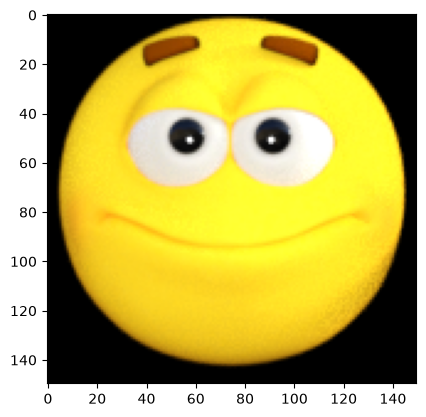


Sample sad image:


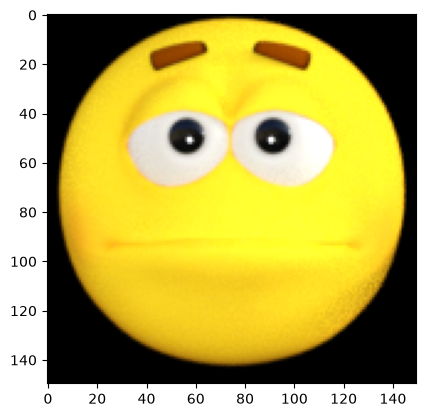

In [4]:
# grader-required-cell

from tensorflow.keras.preprocessing.image import load_img

base_dir = "./data/"
happy_dir = os.path.join(base_dir, "happy/")
sad_dir = os.path.join(base_dir, "sad/")

print("Sample happy image:")
plt.imshow(load_img(f"{os.path.join(happy_dir, os.listdir(happy_dir)[0])}"))
plt.show()

print("\nSample sad image:")
plt.imshow(load_img(f"{os.path.join(sad_dir, os.listdir(sad_dir)[0])}"))
plt.show()


It is cool to be able to see examples of the images to better understand the problem-space you are dealing with.

However there is still some relevant information that is missing such as the resolution of the image (although matplotlib renders the images in a grid providing a good idea of these values) and the maximum pixel value (this is important for normalizing these values). For this you can use Keras as shown in the next cell:

In [5]:
# grader-required-cell

from tensorflow.keras.preprocessing.image import img_to_array

# Load the first example of a happy face
sample_image  = load_img(f"{os.path.join(happy_dir, os.listdir(happy_dir)[0])}")

# Convert the image into its numpy array representation
sample_array = img_to_array(sample_image)

print(f"Each image has shape: {sample_array.shape}")

print(f"The maximum pixel value used is: {np.max(sample_array)}")



Each image has shape: (150, 150, 3)
The maximum pixel value used is: 255.0


Looks like the images have a resolution of 150x150. **This is very important because this will be the input size of the first layer in your network.**

**The last dimension refers to each one of the 3 RGB channels that are used to represent colored images.**

## Defining the callback

Since you already have coded the callback responsible for stopping training (once a desired level of accuracy is reached) in the previous assignments this time it is already provided so you can focus on the other steps:

In [6]:
# grader-required-cell

class myCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs={}):
        if logs.get('accuracy') is not None and logs.get('accuracy') > 0.999:
            print("\nДосягнуто 99,9% точності, тому скасовуємо навчання!")
            self.model.stop_training = True

A quick note on callbacks:

So far you have used only the `on_epoch_end` callback but there are many more. For example you might want to check out the [EarlyStopping](https://www.tensorflow.org/api_docs/python/tf/keras/callbacks/EarlyStopping) callback, which allows you to save the best weights for your model.

## Pre-processing the data

Keras provides great support for preprocessing image data. A lot can be accomplished by using the `ImageDataGenerator` class. Be sure to check out the [docs](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator) if you get stuck in the next exercise. In particular you might want to pay attention to the `rescale` argument when instantiating the `ImageDataGenerator` and to the [`flow_from_directory`](https://www.tensorflow.org/api_docs/python/tf/keras/preprocessing/image/ImageDataGenerator#flow_from_directory) method.

In [7]:
# grader-required-cell

from tensorflow.keras.preprocessing.image import ImageDataGenerator

# GRADED FUNCTION: image_generator
def image_generator():
    ### START CODE HERE
    # Генератор зображень з нормалізацією пікселів у діапазон [0, 1]
    train_datagen = ImageDataGenerator(rescale=1. / 255)

    # Зображення 150x150, пакет по 10, бінарні мітки (happy=0, sad=1)
    train_generator = train_datagen.flow_from_directory(directory="./data/",
                                                        target_size=(150, 150),
                                                        batch_size=10,
                                                        class_mode="binary")
    ### END CODE HERE

    return train_generator


In [8]:
# grader-required-cell

# Save your generator in a variable
gen = image_generator()



Found 80 images belonging to 2 classes.


**Expected Output:**
```
Found 80 images belonging to 2 classes.
```

## Creating and training your model

Finally, complete the `train_happy_sad_model` function below. This function should return your  neural network.

**Your model should achieve an accuracy of 99.9% or more before 15 epochs to pass this assignment.**

**Hints:**
- You can try any architecture for the network but keep in mind that the model will work best with 3 convolutional layers.


In [9]:
# grader-required-cell

from tensorflow.keras import optimizers, losses

# GRADED FUNCTION: train_happy_sad_model
def train_happy_sad_model(train_generator):

    # Instantiate the callback
    callbacks = myCallback()

    ### START CODE HERE
    # Три пари Conv2D + MaxPooling, далі повнозв'язні шари
    model = tf.keras.models.Sequential([
        tf.keras.layers.Conv2D(16, (3, 3), activation="relu", input_shape=(150, 150, 3)),
        tf.keras.layers.MaxPooling2D(2, 2),
        tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D(2, 2),
        tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
        tf.keras.layers.MaxPooling2D(2, 2),
        tf.keras.layers.Flatten(),
        tf.keras.layers.Dense(512, activation="relu"),
        tf.keras.layers.Dense(1, activation="sigmoid"),
    ])

    # Один вихідний нейрон із sigmoid -> binary crossentropy
    model.compile(loss=losses.BinaryCrossentropy(),
                  optimizer=optimizers.RMSprop(learning_rate=0.001),
                  metrics=["accuracy"])

    # Навчання має досягти 99.9% менш ніж за 15 епох; callback зупиняє раніше
    history = model.fit(x=train_generator,
                        epochs=15,
                        callbacks=[callbacks]
                       )

    # Збереження чисел для звіту (у межах дозволеного блоку)
    import json
    from pathlib import Path

    results_dir = (Path("/content") if IN_COLAB else Path.cwd().parent) / "results" / "raw"
    results_dir.mkdir(parents=True, exist_ok=True)
    (results_dir / "task3.json").write_text(json.dumps({
        "task": "task3_happy_or_sad",
        "epochs_planned": 15,
        "epochs_done": len(history.history["accuracy"]),
        "target_accuracy": 0.999,
        "reached_accuracy": round(float(history.history["accuracy"][-1]), 4),
        "history": {k: [round(float(v), 4) for v in vals] for k, vals in history.history.items()},
        "total_params": int(model.count_params()),
        "samples": int(train_generator.samples),
        "class_indices": train_generator.class_indices,
    }, ensure_ascii=False, indent=2), encoding="utf-8")
    ### END CODE HERE
    return history

In [10]:
# grader-required-cell

hist = train_happy_sad_model(gen)

C:\uni_year_4\dl\lab7\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/15


1/8 ━━━━━━━━━━━━━━━━━━━━ 8s 1s/step - accuracy: 0.8000 - loss: 0.6779

2/8 ━━━━━━━━━━━━━━━━━━━━ 0s 160ms/step - accuracy: 0.6500 - loss: 4.9392

3/8 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step - accuracy: 0.5000 - loss: 3.9431

...

5/8 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step - accuracy: 1.0000 - loss: 0.0407

6/8 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 1.0000 - loss: 0.0392

7/8 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 1.0000 - loss: 0.0358

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step - accuracy: 1.0000 - loss: 0.0327


Досягнуто 99,9% точності, тому скасовуємо навчання!
8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 134ms/step - accuracy: 1.0000 - loss: 0.0327


If you see the message that was defined in the callback printed out after less than 15 epochs it means your callback worked as expected and training was successful. You can also double check by running the following cell:

In [11]:
# grader-required-cell

print(f"Your model reached the desired accuracy after {len(hist.epoch)} epochs")

Your model reached the desired accuracy after 7 epochs


If your callback didn't stop training, one cause might be that you compiled your model using a metric other than `accuracy` (such as `acc`). Make sure you set the metric to `accuracy`. You can check by running the following cell:

In [12]:
if not "accuracy" in hist.model.metrics_names:
    print("Use 'accuracy' as metric when compiling your model.")
else:
    print("The metric was correctly defined.")

Use 'accuracy' as metric when compiling your model.


**Congratulations!**

You have successfully implemented a CNN to assist you in the classification task for complex images. Nice job!

**Keep it up!**